# Faixa dividida · split-range

**Um comando. A água quente atua primeiro; quando ela não basta, entra o aquecedor.**

Controlar a temperatura de um ambiente. O diferencial está em decidir
qual recurso usar, mantendo um único PI. Execute de cima para baixo.

In [1]:
%pip -q install control==0.10.2 scipy matplotlib ipywidgets

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as controles
import control as sistema
from scipy import signal
from scipy.optimize import least_squares
from IPython.display import display

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

plt.rcParams.update({"figure.figsize": (9, 3), "axes.grid": True,
                     "grid.alpha": 0.2, "font.size": 10})

## O processo

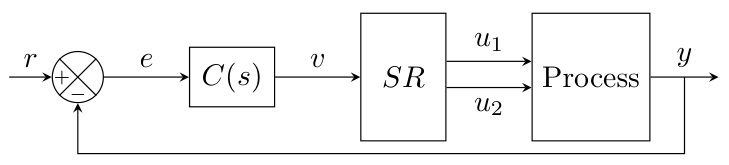

Usar dois canais térmicos publicados, com a temperatura externa fixa em 17 °C:

$$G_{agua}(s)=\frac{12e^{-3s}}{10s+1},\qquad
G_{eletrico}(s)=\frac{8e^{-s}}{5s+1}.$$

A entrada vai de 0 a 1; a saída é o aumentar de temperatura em °C; o tempo está em minutos.
Com água quente sozinha, a temperatura chega no máximo a 29 °C nesse modelo.
Com os dois recursos, chega a 37 °C.

In [3]:
nomes = ['Água quente', 'Aquecedor elétrico']
modelos = np.array([[12.0, 10.0, 3.0], [8.0, 5.0, 1.0]])  # K, τ, θ
temperatura_externa = 17.0
unidade_tempo = 'Tempo (min)'
unidade_saida = 'Aumento de temperatura (°C)'

## Primeiro, repartir o comando

Até 60%, abrir somente a água quente. Acima disso, ela fica totalmente aberta
e o aquecedor começa a atuar. Essa divisão iguala os ganhos estáticos nas duas faixas.
Mova o comando e veja as aberturas.

In [4]:
def dividir_comando(comando, ponto_divisao=0.60):
    agua = np.clip(comando / ponto_divisao, 0, 1)
    eletrico = np.clip((comando - ponto_divisao) / (1 - ponto_divisao), 0, 1)
    return np.array([agua, eletrico])

def ver_aberturas(comando=40):
    aberturas = dividir_comando(comando / 100)
    figura, eixo = plt.subplots(figsize=(7, 2.4))
    eixo.barh(nomes, 100 * aberturas, color=['#2374ab', '#df752c'])
    eixo.set(xlim=(0, 100), xlabel='Abertura (%)', title=f'Comando único: {comando}%')
    plt.show()

display(controles.interactive(ver_aberturas, comando=controles.IntSlider(
    value=40, min=0, max=100, step=5, description='Comando', continuous_update=False)))

interactive(children=(IntSlider(value=40, continuous_update=False, description='Comando', step=5), Output()), …

## Os ensaios

Separar **ensaio → dados → identificação → escolha → validação → IMC**.
Gerar três ensaios diferentes por canal, com ruído, e salvar os arquivos CSV.
Estes dados são simulados; a identificação terá acesso apenas aos arquivos.

Para usar dados próprios, enviar os seis CSV para `dados_ensaio/` e mudar
`usar_ensaio_externo` para `True`. Usar `tempo,entrada,saida`, amostragem uniforme
e variáveis em desvio do ponto de operação; iniciar em equilíbrio com entrada zero.

In [5]:
def guardar_ensaio(nome, tempo, entrada, saida):
    pasta = Path('dados_ensaio')
    pasta.mkdir(exist_ok=True)
    np.savetxt(pasta / f'{nome}.csv', np.column_stack([tempo, entrada, saida]),
               delimiter=',', header='tempo,entrada,saida', comments='')

In [6]:
def resposta_modelo(tempo, entrada, parametros):
    ganho, constante, atraso = parametros
    variacoes = np.diff(entrada, prepend=0)
    saida = np.zeros_like(tempo)
    for indice in np.flatnonzero(variacoes):
        decorrido = np.maximum(tempo - tempo[indice] - atraso, 0)
        saida += ganho * variacoes[indice] * (1 - np.exp(-decorrido / constante))
    return saida

In [7]:
usar_ensaio_externo = False
canais = ['agua', 'eletrico']

if not usar_ensaio_externo:
    tempo_ensaio = np.arange(0, 160 + 0.5 / 2, 0.5)
    entradas = {
        'ajuste': np.where(tempo_ensaio >= 5, 0.25, 0.0),
        'escolha': np.select([tempo_ensaio < 5, tempo_ensaio < 45,
                               tempo_ensaio < 85, tempo_ensaio < 120],
                              [0, 0.15, 0.35, 0.1], default=0.2).astype(float),
        'validacao': np.select([tempo_ensaio < 5, tempo_ensaio < 35,
                               tempo_ensaio < 70, tempo_ensaio < 110,
                               tempo_ensaio < 140],
                              [0, 0.3, 0.1, 0.25, 0.05], default=0).astype(float)}
    for numero, (etapa, entrada) in enumerate(entradas.items()):
        gerador = np.random.default_rng(8400 + numero)
        for canal, planta in zip(canais, modelos):
            medicao = resposta_modelo(tempo_ensaio, entrada, planta)
            medicao += gerador.normal(0, 0.08, len(tempo_ensaio))
            guardar_ensaio(f'{etapa}_{canal}', tempo_ensaio, entrada, medicao)
    print('Salvar três ensaios por canal em dados_ensaio/.')

Salvar três ensaios por canal em dados_ensaio/.


## Ler os dados

Ler os arquivos sem fornecer os parâmetros da planta ao identificador.
Reservar o último ensaio para conferir o modelo depois da escolha.

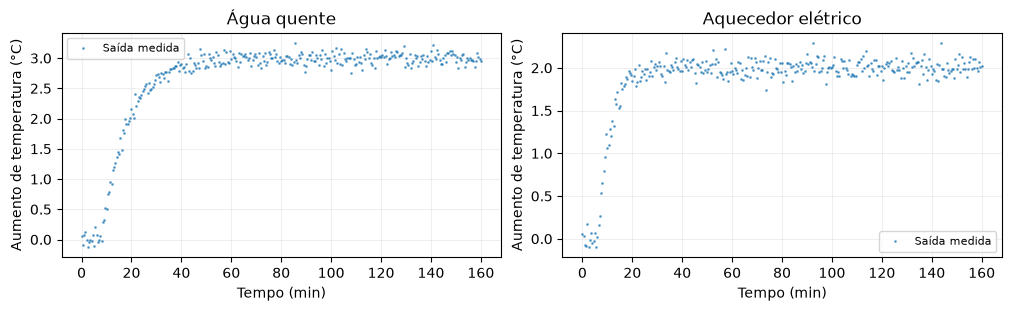

In [8]:
def ler_ensaio(nome):
    dados = np.genfromtxt(Path('dados_ensaio') / f'{nome}.csv', delimiter=',', names=True)
    tempo, entrada, saida = [np.asarray(dados[c], float) for c in ('tempo', 'entrada', 'saida')]
    if len(tempo) < 20 or not np.all(np.isfinite([tempo, entrada, saida])):
        raise ValueError('Fornecer pelo menos 20 amostras finitas de tempo, entrada e saída.')
    if not np.all(np.diff(tempo) > 0) or not np.allclose(np.diff(tempo), np.diff(tempo)[0]):
        raise ValueError('Usar amostragem uniforme, com tempo crescente.')
    if abs(entrada[0]) > 1e-10:
        raise ValueError('Remover o ponto de operação da entrada; iniciar em desvio zero.')
    return tempo - tempo[0], entrada, saida

ensaios = {canal: {etapa: ler_ensaio(f'{etapa}_{canal}')
                  for etapa in ('ajuste', 'escolha', 'validacao')}
           for canal in canais}
figura, eixos = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
for canal, nome, eixo in zip(canais, nomes, eixos):
    tempo, entrada, saida = ensaios[canal]['ajuste']
    eixo.plot(tempo, saida, '.', ms=2, alpha=0.6, label='Saída medida')
    eixo.set(title=nome, xlabel=unidade_tempo, ylabel=unidade_saida)
    eixo.legend(fontsize=8)
plt.show()

## Identificar P1D, P2D ou P3D

Testar um, dois ou três polos reais estáveis, sempre com atraso identificado:
$G(s)=K e^{-\theta s}/\prod_i(\tau_i s+1)$.
P1D tem 3 parâmetros; P2D, 4; P3D, 5. Ajustar somente no ensaio de ajuste.

In [9]:
def prever_modelo(modelo, ensaio):
    tempo, entrada, _ = ensaio
    denominador = np.array([1.0])
    for constante in modelo['constantes']:
        denominador = np.convolve(denominador, [constante, 1.0])
    entrada_atrasada = np.interp(tempo - modelo['atraso'], tempo, entrada, left=0)
    numerador, denominador, _ = signal.cont2discrete(
        ([modelo['ganho']], denominador), tempo[1] - tempo[0], method='zoh')
    return signal.lfilter(numerador.ravel(), denominador, entrada_atrasada)

def avaliar_modelo(modelo, ensaio):
    previsao = prever_modelo(modelo, ensaio)
    erro = ensaio[2] - previsao
    escala = np.linalg.norm(ensaio[2] - np.mean(ensaio[2]))
    ajuste = 100 * (1 - np.linalg.norm(erro) / escala) if escala > 0 else np.nan
    return ajuste, np.sqrt(np.mean(erro ** 2))

In [10]:
def identificar_modelo(ensaio, ordem):
    tempo, entrada, saida = ensaio
    duracao, passo = tempo[-1], tempo[1] - tempo[0]
    cauda = slice(-max(10, len(tempo) // 10), None)
    ganho_inicial = abs(np.median(saida[cauda]) / np.median(entrada[cauda]))
    if not np.isfinite(ganho_inicial) or ganho_inicial <= 0:
        raise ValueError('Usar um ensaio de ajuste com patamar final diferente de zero.')
    def montar(parametros):
        return {'ganho': parametros[0], 'constantes': np.sort(parametros[1:-1]),
                'atraso': parametros[-1], 'parametros': ordem + 2}
    limites = ([ganho_inicial / 20] + [passo / 10] * ordem + [0],
               [ganho_inicial * 20] + [duracao * 2] * ordem + [duracao / 4])
    ajustes = []
    for fracao in (0.06, 0.18):
        constantes = (np.geomspace(max(passo / 5, duracao * 0.002), duracao * fracao, ordem)
                      if ordem > 1 else [duracao * fracao])
        inicio = [ganho_inicial, *constantes, passo]
        ajuste = least_squares(lambda p: prever_modelo(montar(p), ensaio) - saida,
                               inicio, bounds=limites, x_scale='jac', max_nfev=250)
        ajustes.append(ajuste)
    melhor = min(ajustes, key=lambda resultado: resultado.cost)
    if not melhor.success:
        raise RuntimeError('O ajuste não convergiu; revisar o ensaio antes da sintonia.')
    return montar(melhor.x)

In [11]:
candidatos = {canal: {f'P{ordem}D': identificar_modelo(ensaios[canal]['ajuste'], ordem)
                       for ordem in (1, 2, 3)} for canal in canais}
print('Ajustar somente os dados do primeiro ensaio.')

Ajustar somente os dados do primeiro ensaio.


## Escolher com parcimônia

Comparar o **FIT em outro ensaio**. Aceitar até 1 ponto percentual abaixo do melhor
FIT e preferir menos parâmetros. Um modelo maior só compensa se melhorar o resultado.

In [12]:
def escolher_modelo(candidatos, ensaio_escolha, tolerancia=1.0):
    ajustes = {nome: avaliar_modelo(modelo, ensaio_escolha)[0]
               for nome, modelo in candidatos.items()}
    melhor = max(ajustes.values())
    elegiveis = [nome for nome in candidatos if ajustes[nome] >= melhor - tolerancia]
    return min(elegiveis, key=lambda nome: (candidatos[nome]['parametros'], -ajustes[nome]))

def reduzir_modelo(modelo):
    return np.array([modelo['ganho'], np.sum(modelo['constantes']), modelo['atraso']])

selecionados = {canal: escolher_modelo(candidatos[canal], ensaios[canal]['escolha'])
                for canal in canais}
print(f'{"Canal":<20} {"Modelo":<8} {"Parâmetros":>10} {"FIT escolha":>12}  Seleção')
for canal, nome in zip(canais, nomes):
    for estrutura, modelo in candidatos[canal].items():
        ajuste, _ = avaliar_modelo(modelo, ensaios[canal]['escolha'])
        marca = '← parcimonioso' if estrutura == selecionados[canal] else ''
        print(f'{nome:<20} {estrutura:<8} {modelo["parametros"]:>10} {ajuste:>11.2f}%  {marca}')
estimativas = np.array([reduzir_modelo(candidatos[canal][selecionados[canal]])
                        for canal in canais])

Canal                Modelo   Parâmetros  FIT escolha  Seleção
Água quente          P1D               3       92.33%  ← parcimonioso
Água quente          P2D               4       92.31%  
Água quente          P3D               5       92.31%  
Aquecedor elétrico   P1D               3       89.94%  ← parcimonioso
Aquecedor elétrico   P2D               4       89.93%  
Aquecedor elétrico   P3D               5       89.93%  


## Validar sem reajustar

Usar o terceiro ensaio com os modelos já escolhidos. Comparar as curvas e o RMSE;
um FIT alto no ensaio de escolha não substitui esta conferência.

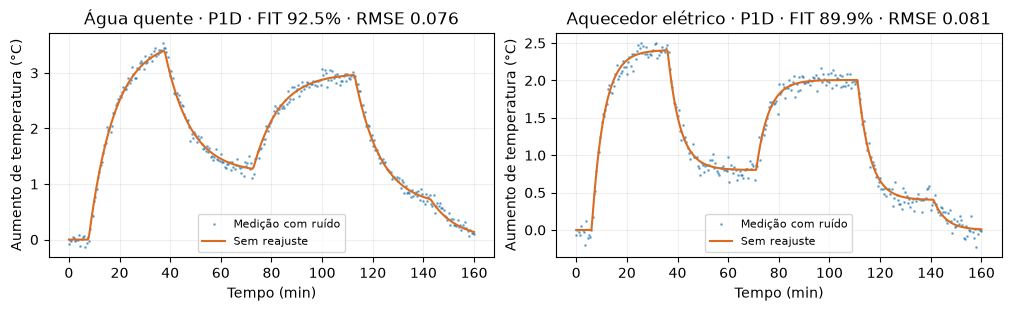

In [13]:
figura, eixos = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
for canal, nome, eixo in zip(canais, nomes, eixos):
    ensaio = ensaios[canal]['validacao']
    modelo = candidatos[canal][selecionados[canal]]
    ajuste, rmse = avaliar_modelo(modelo, ensaio)
    eixo.plot(ensaio[0], ensaio[2], '.', ms=2, alpha=0.5, label='Medição com ruído')
    eixo.plot(ensaio[0], prever_modelo(modelo, ensaio), color='#db6b20', label='Sem reajuste')
    eixo.set(title=f'{nome} · {selecionados[canal]} · FIT {ajuste:.1f}% · RMSE {rmse:.3f}',
             xlabel=unidade_tempo, ylabel=unidade_saida)
    eixo.legend(fontsize=8)
plt.show()

## Sintonia IMC

A divisão será calculada pelas estimativas: $p=K_agua/(K_agua+K_eletrico)$.
Assim, o ganho de cada faixa fica $K_agua+K_eletrico$.
Para o PI único, adotar a dinâmica mais lenta como aproximação de projeto:
$\tau=\max(\tau_i)$, $\theta=\max(\theta_i)$.

Para P2D/P3D, reduzir para primeira ordem usando $\tau=\sum_i\tau_i$, mantendo
ganho e atraso. Essa aproximação preserva o primeiro momento; o PI-IMC usa
o modelo reduzido. A simulação final usa a seleção parcimoniosa.

In [14]:
def sintonia_imc(parametros, tempo_resposta):
    ganho, constante, atraso = parametros
    ganho_controlador = constante / (ganho * (tempo_resposta + atraso))
    tempo_integral = constante
    return ganho_controlador, tempo_integral

def comando_pi(erro, integral, ganho, tempo_integral, passo):
    tentativa = ganho * erro + integral
    comando = np.clip(tentativa, 0, 1)
    # Evitar acumular integral quando a ação empurra além do limite.
    if 0 < tentativa < 1 or (tentativa >= 1 and erro < 0) or (tentativa <= 0 and erro > 0):
        integral += ganho * erro * passo / tempo_integral
    return comando, integral

ganho_equivalente = estimativas[:, 0].sum()
ponto_divisao = estimativas[0, 0] / ganho_equivalente
modelo_projeto = np.array([ganho_equivalente, estimativas[:, 1].max(),
                          estimativas[:, 2].max()])
print(f'Divisão estimada: {100 * ponto_divisao:.1f}%')
print('Kc e Ti do PI único:', np.round(sintonia_imc(modelo_projeto, 12), 3))

Divisão estimada: 59.9%
Kc e Ti do PI único: [ 0.035 10.275]


## Comparar as sintonias

Selecionar um ou mais modelos. Cada curva usa o PI-IMC obtido daquele modelo,
mas todos controlam **o mesmo canal da planta**. Alterar λ para observar a resposta.
Este painel serve para comparar; a experiência final mantém os modelos parcimoniosos.

In [15]:
def comparar_sintonias(canal=canais[0], estruturas=('P1D', 'P2D', 'P3D'), tempo_resposta=12):
    indice = canais.index(canal)
    ganho, constante, atraso = modelos[indice]
    numerador_atraso, denominador_atraso = sistema.pade(atraso, 3)
    planta = sistema.tf([ganho], [constante, 1]) * sistema.tf(numerador_atraso, denominador_atraso)
    tempo = np.linspace(0, 160, 500)
    figura, eixo = plt.subplots(figsize=(9, 3))
    for estrutura in estruturas:
        parametros = reduzir_modelo(candidatos[canal][estrutura])
        ganho_pi, tempo_integral = sintonia_imc(parametros, tempo_resposta)
        controlador = sistema.tf([ganho_pi * tempo_integral, ganho_pi], [tempo_integral, 0])
        malha = sistema.feedback(controlador * planta)
        if np.any(sistema.poles(malha).real >= 0):
            print(f'{estrutura}: sintonia instável; aumentar λ.')
            continue
        _, resposta = sistema.step_response(malha, tempo)
        eixo.plot(tempo, resposta, label=f'{estrutura} · Kc={ganho_pi:.2f}, Ti={tempo_integral:.2f}')
    eixo.axhline(1, color='#666666', ls='--', label='Referência')
    eixo.set(title=f'{nomes[indice]} · comparar na mesma planta',
             xlabel=unidade_tempo, ylabel=unidade_saida)
    eixo.legend(fontsize=8)
    plt.show()

painel_sintonia = controles.interactive(
    comparar_sintonias,
    canal=controles.Dropdown(options=list(zip(nomes, canais)), description='Canal'),
    estruturas=controles.SelectMultiple(options=['P1D', 'P2D', 'P3D'],
                                        value=('P1D', 'P2D', 'P3D'), description='Modelos'),
    tempo_resposta=controles.IntSlider(value=12, min=12, max=36, step=2,
                                       description='IMC λ', continuous_update=False))
display(painel_sintonia)

interactive(children=(Dropdown(description='Canal', options=(('Água quente', 'agua'), ('Aquecedor elétrico', '…

## A simulação

Comparar água quente sozinha com os dois recursos. A referência muda em 10 min.
O divisor e o PI usam as estimativas; a planta usa os modelos publicados.
A aproximação da sintonia não iguala a dinâmica dos recursos.

In [16]:
def simular_faixa(referencia=33, tempo_resposta=12, dois_recursos=True, passo=0.05):
    tempo = np.arange(0, 240 + passo / 2, passo)
    temperatura = np.full(len(tempo), temperatura_externa)
    aberturas = np.zeros((len(tempo), 2))
    comandos = np.zeros(len(tempo))
    contribuicoes = np.zeros(2)
    integral = 0.0
    ganho, tempo_integral = sintonia_imc(modelo_projeto, tempo_resposta)
    atenuacoes = np.exp(-passo / modelos[:, 1])
    atrasos = np.rint(modelos[:, 2] / passo).astype(int)
    for indice in range(len(tempo) - 1):
        desejada = referencia if tempo[indice] >= 10 else temperatura_externa
        limite = 1 if dois_recursos else ponto_divisao
        erro = desejada - temperatura[indice]
        tentativa = ganho * erro + integral
        comandos[indice] = np.clip(tentativa, 0, limite)
        # Integrar somente se o limite não impedir a correção pedida.
        if 0 < tentativa < limite or (tentativa >= limite and erro < 0) or (tentativa <= 0 and erro > 0):
            integral += ganho * erro * passo / tempo_integral
        aberturas[indice] = dividir_comando(comandos[indice], ponto_divisao)
        for canal in range(2):
            anterior = indice - atrasos[canal]
            atrasado = aberturas[max(anterior, 0), canal]
            contribuicoes[canal] = (atenuacoes[canal] * contribuicoes[canal]
                                    + (1 - atenuacoes[canal]) * modelos[canal, 0] * atrasado)
        temperatura[indice + 1] = temperatura_externa + contribuicoes.sum()
    aberturas[-1] = aberturas[-2]
    comandos[-1] = comandos[-2]
    return tempo, temperatura, aberturas, comandos

In [17]:
def explorar_faixa(referencia=33, tempo_resposta=12):
    tempo, temperatura, aberturas, _ = simular_faixa(referencia, tempo_resposta, True)
    _, so_agua, _, _ = simular_faixa(referencia, tempo_resposta, False)
    figura, eixos = plt.subplots(2, 1, figsize=(9, 5), sharex=True, constrained_layout=True)
    eixos[0].plot(tempo, so_agua, label='Só água quente', color='#888888')
    eixos[0].plot(tempo, temperatura, label='Faixa dividida', color='#2374ab')
    eixos[0].plot(tempo, np.where(tempo >= 10, referencia, temperatura_externa),
                  ls='--', color='#555555', label='Referência')
    eixos[0].set(ylabel='Temperatura (°C)', title='Mais capacidade com o segundo recurso')
    eixos[0].legend(fontsize=8)
    eixos[1].plot(tempo, 100 * aberturas[:, 0], label='Água quente')
    eixos[1].plot(tempo, 100 * aberturas[:, 1], label='Aquecedor elétrico')
    eixos[1].set(xlabel='Tempo (min)', ylabel='Abertura (%)', ylim=(-3, 103))
    eixos[1].legend(fontsize=8)
    plt.show()
    limite = temperatura_externa + modelos[:, 0].sum()
    print(f'Limite com os dois recursos: {limite:.0f} °C · temperatura final: {temperatura[-1]:.2f} °C')

painel_faixa = controles.interactive(
    explorar_faixa,
    referencia=controles.IntSlider(value=33, min=22, max=39, step=1,
                                   description='Referência (°C)', continuous_update=False),
    tempo_resposta=controles.IntSlider(value=12, min=8, max=24, step=2,
                                       description='IMC λ (min)', continuous_update=False))
display(painel_faixa)

interactive(children=(IntSlider(value=33, continuous_update=False, description='Referência (°C)', max=39, min=…

## O que observar

- **Referência:** abaixo de 29 °C, a água pode bastar; acima disso, entra o aquecedor.
- **IMC λ:** valores maiores tornam a resposta mais lenta e a atuação menos brusca.
- **Teste 39 °C:** os dois saturam. A faixa dividida não cria capacidade que o processo não tem.

Usar os dois recursos aumenta a faixa atendida; uma sintonia única exige compromisso
entre suas dinâmicas. A teoria e as referências estão no [README](https://github.com/The-Celestino/toolbox-controle-classico/blob/main/estrategias/04_split_range/README.md).

## Referências

1. Luna, J. D. F. O. et al. (2024). *A model predictive control interpretation of the generalized
split-range control*. CBA 2024, 1249–1254.
[Artigo](https://doi.org/10.20906/CBA2024/4340), seção 4 e Tabela 1. Imagem: Figura 1, p. 1249.
A aplicação aqui usa os modelos térmicos para estudar o divisor clássico; não reproduz MPC/GSRC.
2. Longhi, L. G. S. (2017). *Uma heurística fundamental — e normalmente esquecida — para o projeto
de sistemas de controle: justificativa e exemplos industriais*. Revista Técnica da UP, 1(4), 36–75.
[Artigo](https://rtup.petrobras.com.br/rtup/article/download/34/40/64).
3. Rivera, D. E.; Morari, M.; Skogestad, S. (1986). *Internal model control. 4. PID controller design*.
[DOI](https://doi.org/10.1021/i200032a041).